# 实战 Kaggle 比赛：图像分类 (CIFAR-10)
:label:`sec_kaggle_cifar10`

之前几节中，我们一直在使用深度学习框架的高级API直接获取张量格式的图像数据集。
但是在实践中，图像数据集通常以图像文件的形式出现。
本节将从原始图像文件开始，然后逐步组织、读取并将它们转换为张量格式。

我们在 :numref:`sec_image_augmentation`中对CIFAR-10数据集做了一个实验。CIFAR-10是计算机视觉领域中的一个重要的数据集。
本节将运用我们在前几节中学到的知识来参加CIFAR-10图像分类问题的Kaggle竞赛，(**比赛的网址是https://www.kaggle.com/c/cifar-10**)。

 :numref:`fig_kaggle_cifar10`显示了竞赛网站页面上的信息。
为了能提交结果，首先需要注册一个Kaggle账户。

![CIFAR-10 图像分类竞赛页面上的信息。竞赛用的数据集可通过点击“Data”选项卡获取。](../img/kaggle-cifar10.png)
:width:`600px`
:label:`fig_kaggle_cifar10`

首先，导入竞赛所需的包和模块。


In [1]:
import collections
import math
import os
import shutil
import pandas as pd
import torch
import torchvision
from torch import nn
from d2l import torch as d2l

## 获取并组织数据集

比赛数据集分为训练集和测试集，其中训练集包含50000张、测试集包含300000张图像。
在测试集中，10000张图像将被用于评估，而剩下的290000张图像将不会被进行评估，包含它们只是为了防止手动标记测试集并提交标记结果。
两个数据集中的图像都是png格式，高度和宽度均为32像素并有三个颜色通道（RGB）。
这些图片共涵盖10个类别：飞机、汽车、鸟类、猫、鹿、狗、青蛙、马、船和卡车。
 :numref:`fig_kaggle_cifar10`的左上角显示了数据集中飞机、汽车和鸟类的一些图像。

### 下载数据集

登录Kaggle后，我们可以点击 :numref:`fig_kaggle_cifar10`中显示的CIFAR-10图像分类竞赛网页上的“Data”选项卡，然后单击“Download All”按钮下载数据集。
在`../data`中解压下载的文件并在其中解压缩`train.7z`和`test.7z`后，在以下路径中可以找到整个数据集：

* `../data/cifar-10/train/[1-50000].png`
* `../data/cifar-10/test/[1-300000].png`
* `../data/cifar-10/trainLabels.csv`
* `../data/cifar-10/sampleSubmission.csv`

`train`和`test`文件夹分别包含训练和测试图像，`trainLabels.csv`含有训练图像的标签，
`sample_submission.csv`是提交文件的范例。

为了便于入门，[**我们提供包含前1000个训练图像和5个随机测试图像的数据集的小规模样本**]。
要使用Kaggle竞赛的完整数据集，需要将以下`demo`变量设置为`False`。


In [2]:
#@save
d2l.DATA_HUB['cifar10_tiny'] = (d2l.DATA_URL + 'kaggle_cifar10_tiny.zip',
                                '2068874e4b9a9f0fb07ebe0ad2b29754449ccacd')

# 如果使用完整的Kaggle竞赛的数据集，设置demo为False
demo = True

if demo:
    data_dir = d2l.download_extract('cifar10_tiny')
else:
    data_dir = '../data/cifar-10/'

### [**整理数据集**]

我们需要整理数据集来训练和测试模型。
首先，我们用以下函数读取CSV文件中的标签，它返回一个字典，该字典将文件名中不带扩展名的部分映射到其标签。


In [5]:
#@save
def read_csv_labels(fname):
    """读取CSV文件，返回文件名与类别标签的映射字典"""

    with open(fname, 'r') as f:
        lines = f.readlines()[1:]  # 读取所有行，跳过第一行表头

    # 按逗号分割每行，去除末尾换行符
    tokens = [l.rstrip().split(',') for l in lines]

    # 转换为字典：{图片名称: 类别标签}
    return dict(((name, label) for name, label in tokens))


# 读取训练集标签文件
labels = read_csv_labels(os.path.join(data_dir, 'trainLabels.csv'))

print('# 训练样本 :', len(labels))  # 统计训练样本数量
print('# 类别 :', len(set(labels.values())))  # 统计不同类别数量

# 训练样本 : 1000
# 类别 : 10


接下来，我们定义`reorg_train_valid`函数来[**将验证集从原始的训练集中拆分出来**]。
此函数中的参数`valid_ratio`是验证集中的样本数与原始训练集中的样本数之比。
更具体地说，令$n$等于样本最少的类别中的图像数量，而$r$是比率。
验证集将为每个类别拆分出$\max(\lfloor nr\rfloor,1)$张图像。
让我们以`valid_ratio=0.1`为例，由于原始的训练集有50000张图像，因此`train_valid_test/train`路径中将有45000张图像用于训练，而剩下5000张图像将作为路径`train_valid_test/valid`中的验证集。
组织数据集后，同类别的图像将被放置在同一文件夹下。


In [6]:
#@save
def copyfile(filename, target_dir):
    """将文件复制到指定目录"""
    os.makedirs(target_dir, exist_ok=True)  # 创建目标目录，不存在则自动创建
    shutil.copy(filename, target_dir)  # 复制文件


#@save
def reorg_train_valid(data_dir, labels, valid_ratio):
    """按照类别划分训练集和验证集"""

    # 找到样本数量最少的类别，获取该类别的样本数
    n = collections.Counter(labels.values()).most_common()[-1][1]

    # 计算每个类别分配到验证集的样本数量，至少为1
    n_valid_per_label = max(1, math.floor(n * valid_ratio))

    label_count = {}  # 记录各类别已分配的验证样本数量

    # 遍历原始训练集中的所有图片
    for train_file in os.listdir(os.path.join(data_dir, 'train')):

        # 根据文件名获取对应的类别标签
        label = labels[train_file.split('.')[0]]
        fname = os.path.join(data_dir, 'train', train_file)

        # 复制到完整训练集（包含训练集和验证集）
        copyfile(fname, os.path.join(data_dir, 'train_valid_test',
                                     'train_valid', label))

        # 当前类别的验证样本数量未达到要求
        if label not in label_count or label_count[label] < n_valid_per_label:

            # 将图片复制到验证集
            copyfile(fname, os.path.join(data_dir, 'train_valid_test',
                                         'valid', label))

            # 更新当前类别的验证样本数量
            label_count[label] = label_count.get(label, 0) + 1

        else:
            # 剩余图片划分到训练集
            copyfile(fname, os.path.join(data_dir, 'train_valid_test',
                                         'train', label))

    return n_valid_per_label  # 返回每个类别的验证样本数量

In [7]:
train_valid_test/
├── train/             # 训练集
│   ├── cat/
│   └── dog/
├── valid/             # 验证集
│   ├── cat/
│   └── dog/
└── train_valid/       # 完整训练数据
    ├── cat/
    └── dog/

SyntaxError: invalid syntax (2810996236.py, line 1)

下面的`reorg_test`函数用来[**在预测期间整理测试集，以方便读取**]。


In [8]:
#@save
def reorg_test(data_dir):
    """整理测试集目录，方便模型预测"""

    # 遍历原始测试集中的所有图片
    for test_file in os.listdir(os.path.join(data_dir, 'test')):

        # 将测试图片复制到unknown类别目录
        copyfile(
            os.path.join(data_dir, 'test', test_file),  # 原始图片路径
            os.path.join(data_dir, 'train_valid_test',
                         'test', 'unknown')  # 目标目录
        )

In [ ]:
train_valid_test/
├── train/          # 训练集
├── valid/          # 验证集
├── train_valid/    # 完整训练集
└── test/           # 测试集
    └── unknown/    # 所有待预测图片
        ├── 1.png
        ├── 2.png
        └── 3.png

最后，我们使用一个函数来[**调用前面定义的函数**]`read_csv_labels`、`reorg_train_valid`和`reorg_test`。


In [9]:
def reorg_cifar10_data(data_dir, valid_ratio):
    """整理CIFAR-10数据集，划分训练集、验证集和测试集"""

    # 读取训练集标签，建立图片名称与类别的映射关系
    labels = read_csv_labels(os.path.join(data_dir, 'trainLabels.csv'))

    # 按指定比例划分训练集和验证集
    reorg_train_valid(data_dir, labels, valid_ratio)

    # 整理无标签测试集，统一放入unknown目录
    reorg_test(data_dir)

在这里，我们只将样本数据集的批量大小设置为32。
在实际训练和测试中，应该使用Kaggle竞赛的完整数据集，并将`batch_size`设置为更大的整数，例如128。
我们将10％的训练样本作为调整超参数的验证集。


In [10]:
# 演示模式使用32，完整训练模式使用128
batch_size = 32 if demo else 128

valid_ratio = 0.1  # 设置验证集划分比例为10%

# 整理CIFAR-10数据集，划分训练集、验证集和测试集
reorg_cifar10_data(data_dir, valid_ratio)

## [**图像增广**]

我们使用图像增广来解决过拟合的问题。例如在训练中，我们可以随机水平翻转图像。
我们还可以对彩色图像的三个RGB通道执行标准化。
下面，我们列出了其中一些可以调整的操作。


In [11]:
# 定义训练集的数据增强和预处理流程
transform_train = torchvision.transforms.Compose([

    # 将图像缩放，使较短边达到40像素
    torchvision.transforms.Resize(40),

    # 随机裁剪面积为原图 64%～100% 的正方形区域，再缩放为32×32
    torchvision.transforms.RandomResizedCrop(
        32, scale=(0.64, 1.0), ratio=(1.0, 1.0)),

    # 以50%的概率水平翻转图像，增加样本多样性
    torchvision.transforms.RandomHorizontalFlip(),

    # 将图像转换为张量，像素值归一化到[0,1]
    torchvision.transforms.ToTensor(),

    # 按CIFAR-10数据集的均值和标准差，对RGB三个通道分别标准化
    torchvision.transforms.Normalize(
        [0.4914, 0.4822, 0.4465],  # RGB通道均值
        [0.2023, 0.1994, 0.2010]) # RGB通道标准差
])

在测试期间，我们只对图像执行标准化，以消除评估结果中的随机性。


In [12]:
# 定义测试集的图像预处理流程
transform_test = torchvision.transforms.Compose([

    # 将图像转换为张量，像素值缩放到[0,1]
    torchvision.transforms.ToTensor(),

    # 使用CIFAR-10数据集的均值和标准差进行标准化
    torchvision.transforms.Normalize(
        [0.4914, 0.4822, 0.4465],  # RGB三个通道的均值
        [0.2023, 0.1994, 0.2010]) # RGB三个通道的标准差
])

## 读取数据集

接下来，我们[**读取由原始图像组成的数据集**]，每个样本都包括一张图片和一个标签。


In [13]:
# 加载训练集和完整训练集，使用数据增强
train_ds, train_valid_ds = [
    torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'train_valid_test', folder),  # 数据集路径
        transform=transform_train  # 随机裁剪、翻转和标准化
    )
    for folder in ['train', 'train_valid']
]

# 加载验证集和测试集，不使用随机数据增强
valid_ds, test_ds = [
    torchvision.datasets.ImageFolder(
        os.path.join(data_dir, 'train_valid_test', folder),  # 数据集路径
        transform=transform_test  # 张量转换和标准化
    )
    for folder in ['valid', 'test']
]

在训练期间，我们需要[**指定上面定义的所有图像增广操作**]。
当验证集在超参数调整过程中用于模型评估时，不应引入图像增广的随机性。
在最终预测之前，我们根据训练集和验证集组合而成的训练模型进行训练，以充分利用所有标记的数据。


In [14]:
# 创建训练集和完整训练集的数据迭代器
train_iter, train_valid_iter = [
    torch.utils.data.DataLoader(
        dataset,                 # 数据集对象
        batch_size,              # 每批样本数量
        shuffle=True,            # 每轮随机打乱数据
        drop_last=True)          # 丢弃最后不足一个批次的数据
    for dataset in (train_ds, train_valid_ds)
]

# 创建验证集迭代器，不打乱数据
valid_iter = torch.utils.data.DataLoader(
    valid_ds,
    batch_size,
    shuffle=False,  # 保持数据顺序
    drop_last=True) # 丢弃最后不完整的批次

# 创建测试集迭代器
test_iter = torch.utils.data.DataLoader(
    test_ds,
    batch_size,
    shuffle=False,   # 保持顺序，方便对应预测结果和文件名
    drop_last=False) # 保留所有测试样本

## 定义[**模型**]


我们定义了 :numref:`sec_resnet`中描述的Resnet-18模型。


In [15]:
def get_net():
    num_classes = 10
    net = d2l.resnet18(num_classes, 3)
    return net

loss = nn.CrossEntropyLoss(reduction="none")

## 定义[**训练函数**]

我们将根据模型在验证集上的表现来选择模型并调整超参数。
下面我们定义了模型训练函数`train`。


In [16]:
def train(net, train_iter, valid_iter, num_epochs, lr, wd, devices, lr_period,
          lr_decay):
    trainer = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9,
                              weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.StepLR(trainer, lr_period, lr_decay)
    num_batches, timer = len(train_iter), d2l.Timer()
    legend = ['train loss', 'train acc']
    if valid_iter is not None:
        legend.append('valid acc')
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs],
                            legend=legend)
    net = nn.DataParallel(net, device_ids=devices).to(devices[0])
    for epoch in range(num_epochs):
        net.train()
        metric = d2l.Accumulator(3)
        for i, (features, labels) in enumerate(train_iter):
            timer.start()
            l, acc = d2l.train_batch_ch13(net, features, labels,
                                          loss, trainer, devices)
            metric.add(l, acc, labels.shape[0])
            timer.stop()
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                             (metric[0] / metric[2], metric[1] / metric[2],
                              None))
        if valid_iter is not None:
            valid_acc = d2l.evaluate_accuracy_gpu(net, valid_iter)
            animator.add(epoch + 1, (None, None, valid_acc))
        scheduler.step()
    measures = (f'train loss {metric[0] / metric[2]:.3f}, '
                f'train acc {metric[1] / metric[2]:.3f}')
    if valid_iter is not None:
        measures += f', valid acc {valid_acc:.3f}'
    print(measures + f'\n{metric[2] * num_epochs / timer.sum():.1f}'
          f' examples/sec on {str(devices)}')

## [**训练和验证模型**]

现在，我们可以训练和验证模型了，而以下所有超参数都可以调整。
例如，我们可以增加周期的数量。当`lr_period`和`lr_decay`分别设置为4和0.9时，优化算法的学习速率将在每4个周期乘以0.9。
为便于演示，我们在这里只训练20个周期。


train loss 0.630, train acc 0.792, valid acc 0.438
897.5 examples/sec on [device(type='cuda', index=0)]


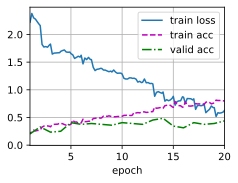

In [17]:
devices, num_epochs, lr, wd = d2l.try_all_gpus(), 20, 2e-4, 5e-4
lr_period, lr_decay, net = 4, 0.9, get_net()
train(net, train_iter, valid_iter, num_epochs, lr, wd, devices, lr_period,
      lr_decay)

## 在 Kaggle 上[**对测试集进行分类并提交结果**]

在获得具有超参数的满意的模型后，我们使用所有标记的数据（包括验证集）来重新训练模型并对测试集进行分类。


train loss 0.591, train acc 0.791
903.2 examples/sec on [device(type='cuda', index=0)]


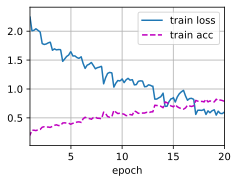

In [18]:
# 创建模型和预测结果列表
net, preds = get_net(), []

# 使用完整训练集（训练集+验证集）训练最终模型
train(net, train_valid_iter, None, num_epochs, lr, wd, devices,
      lr_period, lr_decay)

# 遍历测试集，生成预测结果
net.eval()  # 切换到评估模式
with torch.no_grad():  # 预测时不计算梯度
    for X, _ in test_iter:
        # 将数据移动到GPU，获取每个类别的预测分数
        y_hat = net(X.to(devices[0]))

        # 选择分数最高的类别，并保存预测结果
        preds.extend(
            y_hat.argmax(dim=1).type(torch.int32).cpu().numpy())

# 生成测试图片ID，并按照文件名的字符串顺序排序
sorted_ids = list(range(1, len(test_ds) + 1))
sorted_ids.sort(key=lambda x: str(x))

# 将图片ID和预测类别组合为DataFrame
df = pd.DataFrame({'id': sorted_ids, 'label': preds})

# 将数字类别索引转换为类别名称
df['label'] = df['label'].apply(
    lambda x: train_valid_ds.classes[x])

# 保存为Kaggle提交文件
df.to_csv('submission.csv', index=False)

向Kaggle提交结果的方法与 :numref:`sec_kaggle_house`中的方法类似，上面的代码将生成一个
`submission.csv`文件，其格式符合Kaggle竞赛的要求。

## 小结

* 将包含原始图像文件的数据集组织为所需格式后，我们可以读取它们。


* 我们可以在图像分类竞赛中使用卷积神经网络和图像增广。
